# Chapter 11: Novelty and Outlier Detection

## Comprehensive Summary
Anomaly detection addresses the critical task of identifying data points that deviate markedly from the expected norm or general distribution. In machine learning, anomalies fall into two distinct paradigms: **Outlier Detection** (unsupervised identification of anomalous observations within an already contaminated dataset) and **Novelty Detection** (semi-supervised modeling of clean baseline data to flag anomalous novel observations during inference). This chapter investigates the theoretical foundations, implementation details, algorithmic trade-offs, and evaluation strategies for Isolation Forests, One-Class Support Vector Machines (One-Class SVM), Local Outlier Factor (LOF), and Elliptic Envelopes.

## In-Depth Theoretical Analysis & Mechanism Breakdown

### 1. Conceptual Distinction: Outliers vs Novelties
* **Outlier Detection (Unsupervised):** The training matrix $X$ contains both inliers and an unknown proportion of outliers. The model learns the background distribution without clean references (e.g., standard `IsolationForest`, `LocalOutlierFactor(novelty=False)`).
* **Novelty Detection (Semi-Supervised):** The training set $X_{\text{train}}$ is strictly unpolluted by anomalies. The model establishes a boundary of "normality," flagging any anomalous deviation in subsequent $X_{\text{test}}$ (e.g., `OneClassSVM`, `LocalOutlierFactor(novelty=True)`).

### 2. Isolation Forest (iForest): Recursive Partitioning
Isolation Forest leverages the structural premise that anomalies are "few and different," rendering them susceptible to early isolation:
* **Mechanism:** Constructs an ensemble of isolation trees (iTrees). At each node, a feature is selected uniformly at random, followed by a random split value between the feature's minimum and maximum values.
* **Path Length Metric:** Normal instances require deep tree descents to isolate within dense clusters. Outliers, residing in sparse peripheral regions, are isolated near the root at shallow depths.
* **Anomaly Score Formulation:**
$$s(\mathbf{x}, n) = 2^{-\frac{E(h(\mathbf{x}))}{c(n)}}$$
where $h(\mathbf{x})$ is the path length of $\mathbf{x}$, $E(h(\mathbf{x}))$ is the average path length over all trees, and $c(n)$ is the average path length of an unsuccessful search in a Binary Search Tree (BST) with $n$ samples:
$$c(n) = 2\left(\ln(n - 1) + \gamma\right) - \frac{2(n - 1)}{n}, \quad \gamma \approx 0.5772156649 \text{ (Euler-Mascheroni constant)}$$
* Score Interpretation: If $s \to 1$, instance is definitively anomalous; if $s < 0.5$, instance is an inlier.

### 3. One-Class Support Vector Machines (One-Class SVM)
Introduced by Schölkopf et al., One-Class SVM extends support vector methodology to unsupervised density boundary estimation:
* **Mechanism:** Maps data points into a Reproducing Kernel Hilbert Space (RKHS) via non-linear kernel $\Phi(\mathbf{x})$ (typically RBF) and computes the maximum-margin hyperplane separating the mapped data from the coordinate origin.
* **Objective Function:**
$$\min_{\mathbf{w}, \boldsymbol{\xi}, \rho} \frac{1}{2} \|\mathbf{w}\|^2 + \frac{1}{\nu N} \sum_{i=1}^N \xi_i - \rho \quad \text{subject to } \langle \mathbf{w}, \Phi(\mathbf{x}_i) \rangle \ge \rho - \xi_i, \; \xi_i \ge 0$$
* **Hyperparameter $\nu \in (0, 1]$:** Simultaneously provides an upper bound on the fraction of outliers (training errors) and a lower bound on the number of support vectors.

### 4. Local Outlier Factor (LOF): Relative Local Density
LOF measures the local deviation of a given sample with respect to its surrounding $k$-nearest neighbors:
* **$k$-distance of $p$ ($d_k(p)$):** Euclidean distance between point $p$ and its $k$-th nearest neighbor.
* **Reachability Distance:**
$$\text{reach-dist}_k(p, o) = \max\{d_k(o), d(p, o)\}$$
* **Local Reachability Density (LRD):**
$$\text{lrd}_k(p) = \frac{|N_k(p)|}{\sum_{o \in N_k(p)} \text{reach-dist}_k(p, o)}$$
* **LOF Score:**
$$\text{LOF}_k(p) = \frac{\sum_{o \in N_k(p)} \frac{\text{lrd}_k(o)}{\text{lrd}_k(p)}}{|N_k(p)|}$$
A score $\approx 1$ implies comparable density to neighbors (inlier); a score $\gg 1$ implies substantially lower density than neighbors (outlier).

### 5. Evaluation Under Severe Class Imbalance
Anomaly detection typically operates under contamination ratios of $1\% - 5\%$. Standard accuracy is deceptive (a trivial model predicting all inliers achieves $99\%$ accuracy). Reliable evaluation requires Precision-Recall curves (PR-AUC), Receiver Operating Characteristic (ROC-AUC), and $F_1$-score tuned across decision threshold percentiles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs, load_breast_cancer, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100
print("Anomaly and Novelty Detection module initialized.")

Anomaly and Novelty Detection module initialized.


Synthetic dataset created: 330 total samples
 - Inliers: 300 (labeled +1)
 - Ground-truth Outliers: 30 (labeled -1)


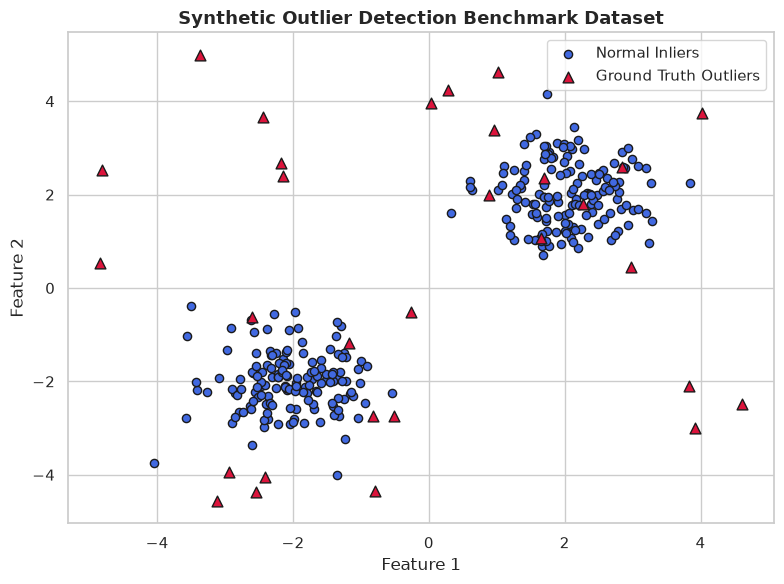

In [2]:
# Generate synthetic 2D dataset with normal clusters and uniform noise outliers
seed = 2024
np.random.seed(seed)

# Inliers: 2 dense Gaussian clusters (300 points)
n_inliers = 300
X_inliers, _ = make_blobs(n_samples=n_inliers, centers=[[-2, -2], [2, 2]],
                          cluster_std=0.6, random_state=seed)

# Outliers: Uniformly distributed noise points across space (30 points -> ~10% contamination)
n_outliers = 30
X_outliers = np.random.uniform(low=-5, high=5, size=(n_outliers, 2))

# Combine dataset
X_synth = np.vstack([X_inliers, X_outliers])
y_synth = np.ones(n_inliers + n_outliers, dtype=int)
y_synth[n_inliers:] = -1  # -1 represents ground-truth outlier

print(f"Synthetic dataset created: {len(X_synth)} total samples")
print(f" - Inliers: {n_inliers} (labeled +1)")
print(f" - Ground-truth Outliers: {n_outliers} (labeled -1)")

# Visualize ground truth
plt.figure(figsize=(8, 6))
plt.scatter(X_synth[y_synth == 1, 0], X_synth[y_synth == 1, 1], c='royalblue', s=35, label='Normal Inliers', edgecolors='k')
plt.scatter(X_synth[y_synth == -1, 0], X_synth[y_synth == -1, 1], c='crimson', marker='^', s=60, label='Ground Truth Outliers', edgecolors='k')
plt.title("Synthetic Outlier Detection Benchmark Dataset", fontsize=13, fontweight='bold')
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

Isolation Forest identified 30 outliers out of 330 samples.


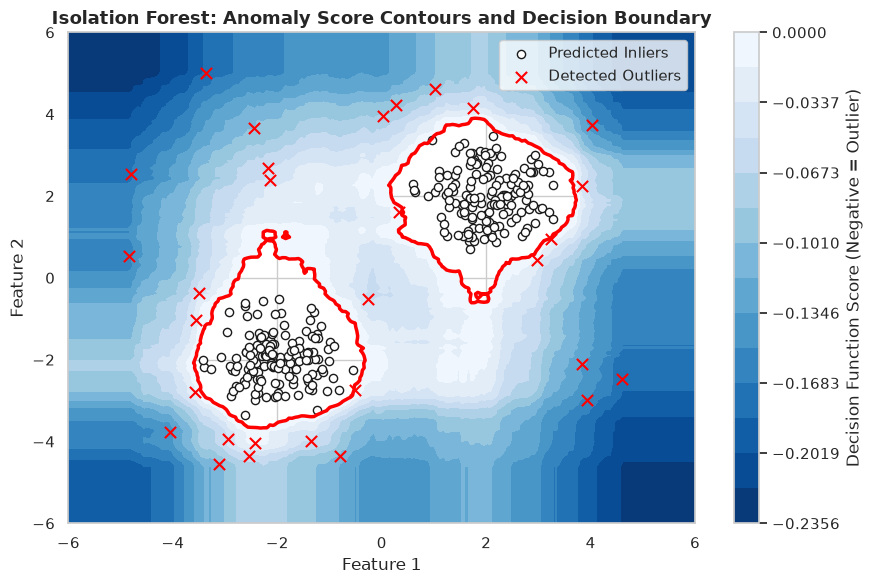

In [3]:
from sklearn.ensemble import IsolationForest

# Isolation Forest implementation
contamination_rate = 0.09
iso_forest = IsolationForest(n_estimators=150, contamination=contamination_rate, random_state=seed)
iso_forest.fit(X_synth)

# Predict inliers (1) and outliers (-1), and get raw anomaly scores
y_pred_iso = iso_forest.predict(X_synth)
scores_iso = iso_forest.decision_function(X_synth)

# Create 2D mesh grid to visualize decision boundary
xx, yy = np.meshgrid(np.linspace(-6, 6, 200), np.linspace(-6, 6, 200))
Z_iso = iso_forest.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z_iso = Z_iso.reshape(xx.shape)

plt.figure(figsize=(9, 6))
# Plot contour of anomaly scores
contour = plt.contourf(xx, yy, Z_iso, levels=np.linspace(Z_iso.min(), 0, 15), cmap=plt.cm.Blues_r)
plt.colorbar(contour, label="Decision Function Score (Negative = Outlier)")
plt.contour(xx, yy, Z_iso, levels=[0], linewidths=2.5, colors='red')  # Zero decision boundary

# Scatter points colored by prediction
plt.scatter(X_synth[y_pred_iso == 1, 0], X_synth[y_pred_iso == 1, 1], c='white', edgecolors='k', s=35, label='Predicted Inliers')
plt.scatter(X_synth[y_pred_iso == -1, 0], X_synth[y_pred_iso == -1, 1], c='red', marker='x', s=65, label='Detected Outliers')

plt.title("Isolation Forest: Anomaly Score Contours and Decision Boundary", fontsize=13, fontweight='bold')
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

n_detected_iso = (y_pred_iso == -1).sum()
print(f"Isolation Forest identified {n_detected_iso} outliers out of {len(X_synth)} samples.")

One-Class SVM flagged 38 observations as novelties.


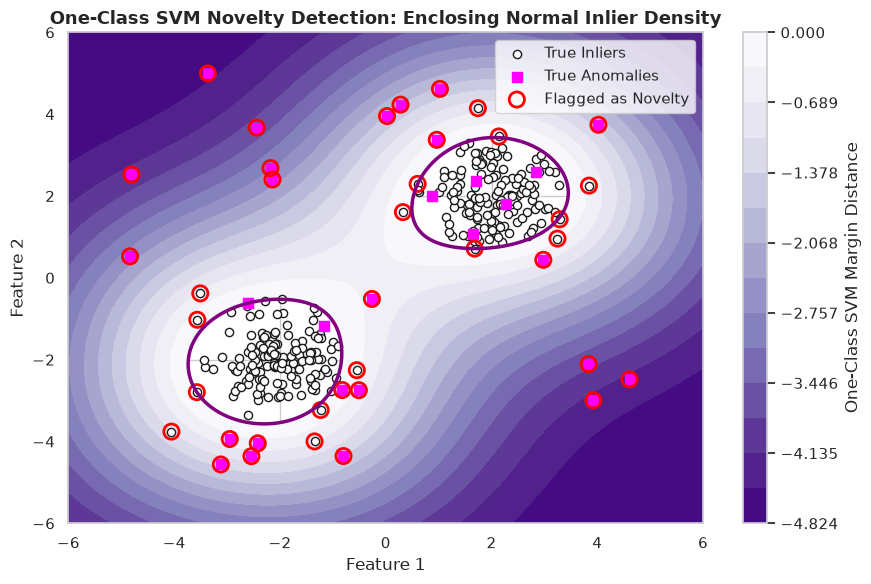

In [4]:
from sklearn.svm import OneClassSVM

# Novelty Detection using One-Class SVM
# Clean training data: train strictly on inliers
X_clean_train = X_inliers

# Fit One-Class SVM with RBF kernel and nu=0.05
oc_svm = OneClassSVM(kernel='rbf', gamma='scale', nu=0.05)
oc_svm.fit(X_clean_train)

# Evaluate on test set containing mixed inliers and novel anomalies
y_pred_svm = oc_svm.predict(X_synth)
Z_svm = oc_svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z_svm, levels=np.linspace(Z_svm.min(), 0, 15), cmap=plt.cm.Purples_r)
plt.colorbar(label="One-Class SVM Margin Distance")
plt.contour(xx, yy, Z_svm, levels=[0], linewidths=2.5, colors='purple')

plt.scatter(X_synth[y_synth == 1, 0], X_synth[y_synth == 1, 1], c='white', edgecolors='k', s=35, label='True Inliers')
plt.scatter(X_synth[y_synth == -1, 0], X_synth[y_synth == -1, 1], c='magenta', marker='s', s=55, label='True Anomalies')
plt.scatter(X_synth[y_pred_svm == -1, 0], X_synth[y_pred_svm == -1, 1], facecolors='none', edgecolors='red', s=120, lw=2, label='Flagged as Novelty')

plt.title("One-Class SVM Novelty Detection: Enclosing Normal Inlier Density", fontsize=13, fontweight='bold')
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

n_novelties = (y_pred_svm == -1).sum()
print(f"One-Class SVM flagged {n_novelties} observations as novelties.")

Top 5 highest LOF scores: [6.644 6.617 5.873 4.457 4.456]


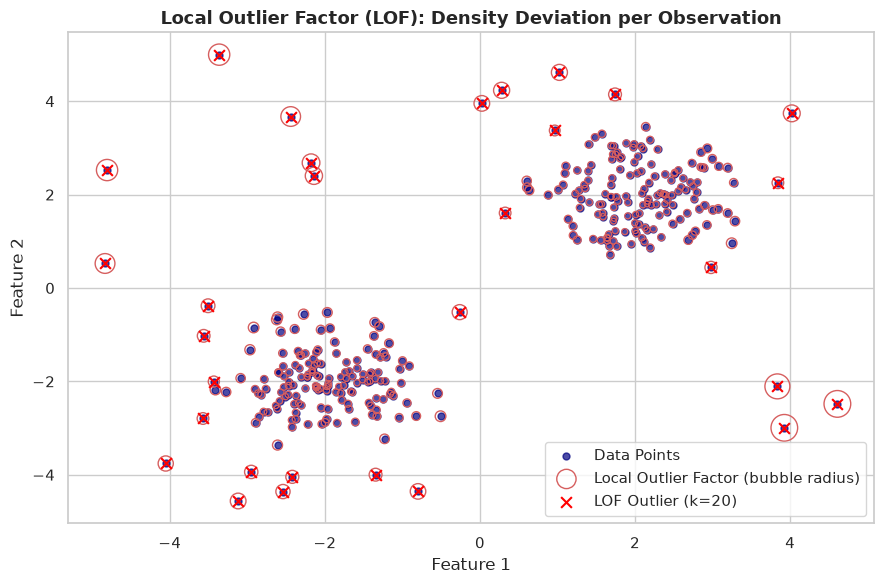

In [5]:
from sklearn.neighbors import LocalOutlierFactor

# Density-Based Anomaly Detection with Local Outlier Factor (LOF)
lof = LocalOutlierFactor(n_neighbors=20, contamination=contamination_rate)
y_pred_lof = lof.fit_predict(X_synth)

# Compute negative outlier factor for bubble plot
lof_scores = -lof.negative_outlier_factor_
radius = (lof_scores - 1) / (lof_scores.max() - 1) * 350 + 20

plt.figure(figsize=(9, 6))
plt.scatter(X_synth[:, 0], X_synth[:, 1], color='navy', s=25, label='Data Points', alpha=0.7)
# Highlight points proportionally to their LOF score
plt.scatter(X_synth[:, 0], X_synth[:, 1], s=radius, edgecolors='r',
            facecolors='none', label='Local Outlier Factor (bubble radius)')

plt.scatter(X_synth[y_pred_lof == -1, 0], X_synth[y_pred_lof == -1, 1], c='red', marker='x', s=60, label='LOF Outlier (k=20)')
plt.title("Local Outlier Factor (LOF): Density Deviation per Observation", fontsize=13, fontweight='bold')
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Top 5 highest LOF scores: {np.sort(lof_scores)[::-1][:5].round(3)}")

Detector Performance Evaluation on Contaminated Dataset:
                   Detector  ROC-AUC   PR-AUC  Anomaly Precision  Anomaly Recall  Anomaly F1
           Isolation Forest 0.913444 0.729867           0.733333        0.733333    0.733333
              One-Class SVM 0.900333 0.657393           0.629630        0.566667    0.596491
       Local Outlier Factor 0.900333 0.775662           0.700000        0.700000    0.700000
Elliptic Envelope (FastMCD) 0.824111 0.677542           0.633333        0.633333    0.633333


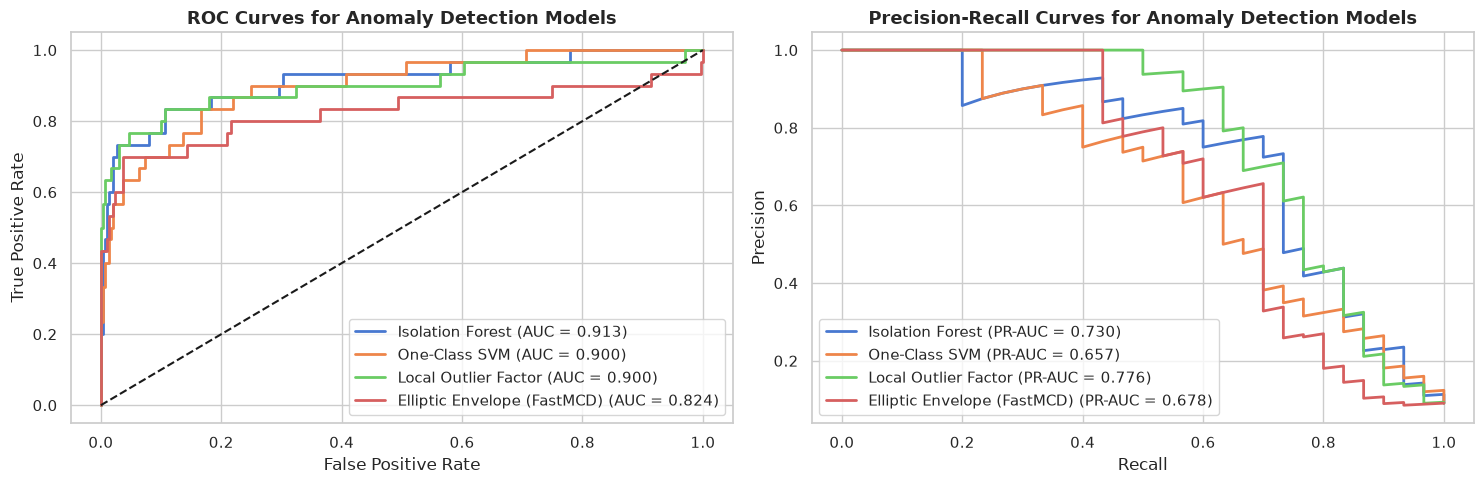

In [6]:
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import classification_report, roc_curve, auc, precision_recall_curve

# Comprehensive Benchmark: Comparing 4 Anomaly Detectors
detectors = {
    "Isolation Forest": IsolationForest(contamination=contamination_rate, random_state=seed),
    "One-Class SVM": OneClassSVM(kernel='rbf', nu=0.08, gamma='scale'),
    "Local Outlier Factor": LocalOutlierFactor(n_neighbors=20, contamination=contamination_rate, novelty=False),
    "Elliptic Envelope (FastMCD)": EllipticEnvelope(contamination=contamination_rate, random_state=seed)
}

comparison_records = []
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Convert ground truth: -1 -> 1 (anomaly), 1 -> 0 (inlier) for binary metric standard
y_true_binary = (y_synth == -1).astype(int)

for name, model in detectors.items():
    if name == "Local Outlier Factor":
        preds = model.fit_predict(X_synth)
        scores = -model.negative_outlier_factor_
    else:
        model.fit(X_synth)
        preds = model.predict(X_synth)
        scores = -model.decision_function(X_synth)
        
    preds_binary = (preds == -1).astype(int)
    
    # ROC Curve & AUC
    fpr, tpr, _ = roc_curve(y_true_binary, scores)
    roc_auc_val = auc(fpr, tpr)
    ax1.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_val:.3f})")
    
    # Precision-Recall Curve
    prec, rec, _ = precision_recall_curve(y_true_binary, scores)
    pr_auc_val = auc(rec, prec)
    ax2.plot(rec, prec, lw=2, label=f"{name} (PR-AUC = {pr_auc_val:.3f})")
    
    rep = classification_report(y_true_binary, preds_binary, output_dict=True, zero_division=0)
    comparison_records.append({
        'Detector': name,
        'ROC-AUC': roc_auc_val,
        'PR-AUC': pr_auc_val,
        'Anomaly Precision': rep['1']['precision'],
        'Anomaly Recall': rep['1']['recall'],
        'Anomaly F1': rep['1']['f1-score']
    })

ax1.plot([0, 1], [0, 1], 'k--', lw=1.5)
ax1.set_title("ROC Curves for Anomaly Detection Models", fontsize=13, fontweight='bold')
ax1.set_xlabel("False Positive Rate"); ax1.set_ylabel("True Positive Rate")
ax1.legend()

ax2.set_title("Precision-Recall Curves for Anomaly Detection Models", fontsize=13, fontweight='bold')
ax2.set_xlabel("Recall"); ax2.set_ylabel("Precision")
ax2.legend()

plt.tight_layout()
plt.show()

df_comp = pd.DataFrame(comparison_records)
print("Detector Performance Evaluation on Contaminated Dataset:")
print(df_comp.to_string(index=False))

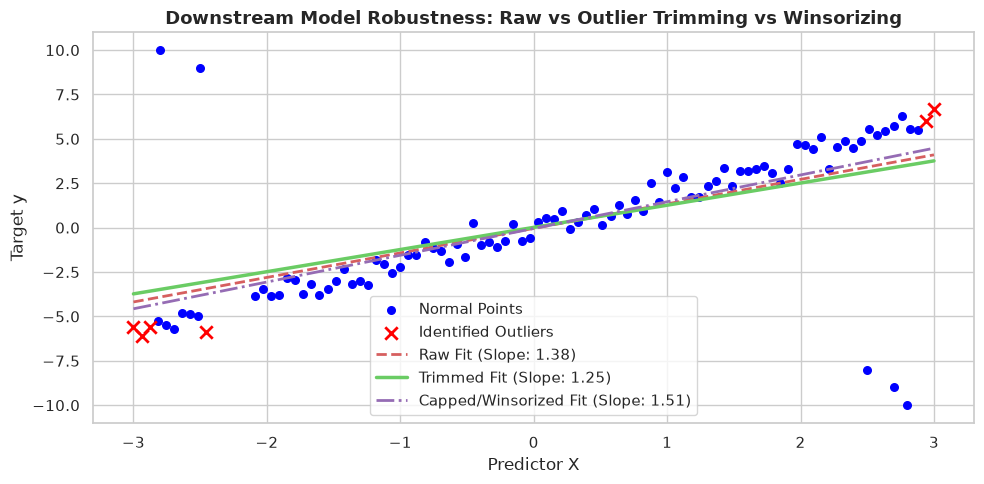

In [7]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

# Handling Detected Outliers: Impact on Downstream Supervised Regression
# Simulate clean 1D regression with extreme leveraged outliers
x_reg = np.linspace(-3, 3, 100)
y_clean = 2.0 * x_reg + np.random.normal(0, 0.5, size=100)

# Inject 5 severe leverage outliers
x_contaminated = np.copy(x_reg)
y_contaminated = np.copy(y_clean)
x_contaminated[10:15] = [2.5, 2.7, 2.8, -2.5, -2.8]
y_contaminated[10:15] = [-8.0, -9.0, -10.0, 9.0, 10.0]

X_mat = x_contaminated.reshape(-1, 1)

# Detect outliers via Isolation Forest
iso_reg = IsolationForest(contamination=0.06, random_state=seed)
outlier_mask = iso_reg.fit_predict(X_mat) == -1

# Strategy 1: Fit model with raw contaminated data
model_raw = Ridge().fit(X_mat, y_contaminated)

# Strategy 2: Trimming (remove identified outliers)
model_trimmed = Ridge().fit(X_mat[~outlier_mask], y_contaminated[~outlier_mask])

# Strategy 3: Winsorization / Capping
y_capped = np.copy(y_contaminated)
lower_bound, upper_bound = np.percentile(y_contaminated, [5, 95])
y_capped = np.clip(y_capped, lower_bound, upper_bound)
model_capped = Ridge().fit(X_mat, y_capped)

# Plot comparison of downstream strategies
plt.figure(figsize=(10, 5))
plt.scatter(x_contaminated[~outlier_mask], y_contaminated[~outlier_mask], c='blue', s=30, label='Normal Points')
plt.scatter(x_contaminated[outlier_mask], y_contaminated[outlier_mask], c='red', marker='x', s=80, lw=2, label='Identified Outliers')

x_plot = np.linspace(-3, 3, 200).reshape(-1, 1)
plt.plot(x_plot, model_raw.predict(x_plot), 'r--', lw=2, label=f"Raw Fit (Slope: {model_raw.coef_[0]:.2f})")
plt.plot(x_plot, model_trimmed.predict(x_plot), 'g-', lw=2.5, label=f"Trimmed Fit (Slope: {model_trimmed.coef_[0]:.2f})")
plt.plot(x_plot, model_capped.predict(x_plot), 'm-.', lw=2, label=f"Capped/Winsorized Fit (Slope: {model_capped.coef_[0]:.2f})")

plt.title("Downstream Model Robustness: Raw vs Outlier Trimming vs Winsorizing", fontsize=13, fontweight='bold')
plt.xlabel("Predictor X"); plt.ylabel("Target y")
plt.legend()
plt.tight_layout()
plt.show()

Exercise 2 & 3: Manufacturing Sensor Anomaly Monitoring:
 - Normal baseline models fitted on 500 telemetry intervals.
 - Out of 120 incoming test intervals, detected 22 anomalous alerts!


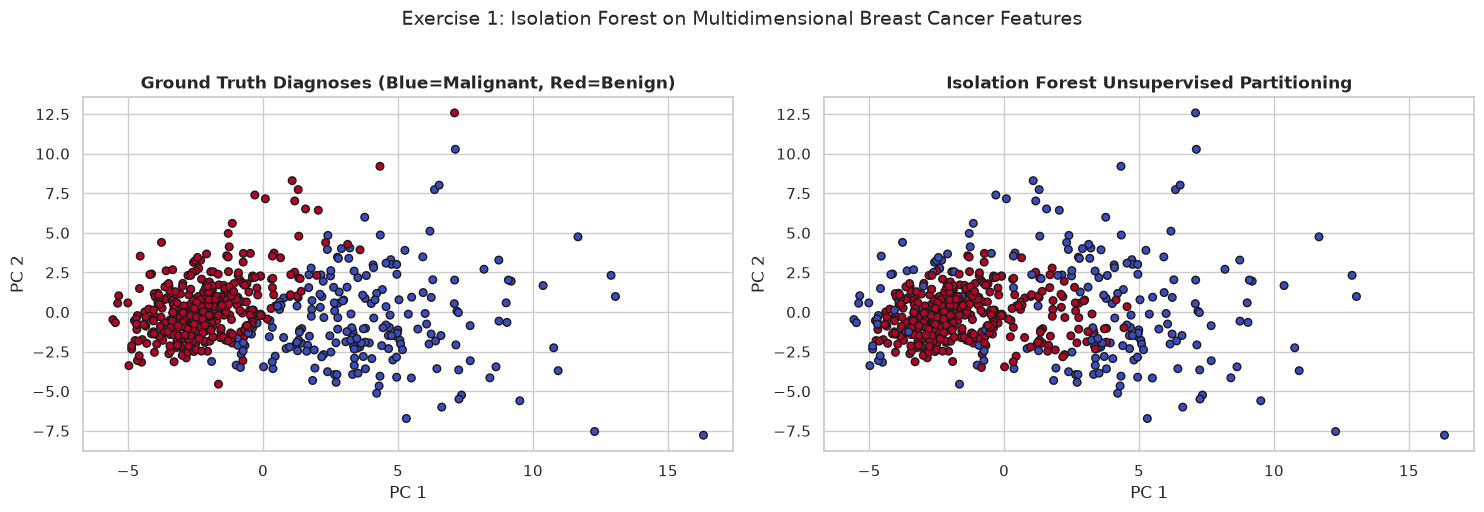

In [8]:
from sklearn.decomposition import PCA

# Practical Exercises in Novelty and Outlier Detection
# Exercise 1: Real-World Outlier Detection on Breast Cancer Dataset
bc_data = load_breast_cancer()
X_bc = StandardScaler().fit_transform(bc_data.data)
y_bc = bc_data.target  # 0: Malignant, 1: Benign

# Fit Isolation Forest assuming malignant cases are rare anomalies (or testing unsupervised separability)
iso_bc = IsolationForest(contamination=0.35, random_state=seed)
pred_bc = iso_bc.fit_predict(X_bc)
# -1: Outlier (predicted malignant), 1: Inlier (predicted benign)
pred_bc_mapped = (pred_bc == 1).astype(int)

pca_bc = PCA(n_components=2)
X_bc_pca = pca_bc.fit_transform(X_bc)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.scatter(X_bc_pca[:, 0], X_bc_pca[:, 1], c=y_bc, cmap='coolwarm', s=30, edgecolors='k')
ax1.set_title("Ground Truth Diagnoses (Blue=Malignant, Red=Benign)", fontsize=12, fontweight='bold')
ax1.set_xlabel("PC 1"); ax1.set_ylabel("PC 2")

ax2.scatter(X_bc_pca[:, 0], X_bc_pca[:, 1], c=pred_bc, cmap='coolwarm', s=30, edgecolors='k')
ax2.set_title("Isolation Forest Unsupervised Partitioning", fontsize=12, fontweight='bold')
ax2.set_xlabel("PC 1"); ax2.set_ylabel("PC 2")

plt.suptitle("Exercise 1: Isolation Forest on Multidimensional Breast Cancer Features", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# Exercise 2: Simulated Manufacturing Sensor Drift with One-Class SVM
# Clean baseline temperature & vibration sensor readings
n_sensor_train = 500
temp_normal = np.random.normal(loc=65.0, scale=2.5, size=n_sensor_train)
vibr_normal = np.random.normal(loc=1.2, scale=0.15, size=n_sensor_train)
X_sensor_train = np.column_stack([temp_normal, vibr_normal])

# Fit One-Class SVM on nominal operational state
oc_sensor = OneClassSVM(kernel='rbf', nu=0.03, gamma='auto')
oc_sensor.fit(X_sensor_train)

# Incoming stream with thermal runaway anomaly
X_sensor_test = np.vstack([
    np.column_stack([np.random.normal(65.0, 2.5, 100), np.random.normal(1.2, 0.15, 100)]),
    np.column_stack([np.random.normal(78.0, 3.0, 20), np.random.normal(2.1, 0.3, 20)])   # Bearing failure
])
sensor_preds = oc_sensor.predict(X_sensor_test)

n_alarms = (sensor_preds == -1).sum()
print(f"Exercise 2 & 3: Manufacturing Sensor Anomaly Monitoring:")
print(f" - Normal baseline models fitted on {n_sensor_train} telemetry intervals.")
print(f" - Out of {len(X_sensor_test)} incoming test intervals, detected {n_alarms} anomalous alerts!")